In [ ]:
# Usually pre-installed, but this ensures compatibility
!pip install cudf-cu12 cuml-cu12 --extra-index-url=https://pypi.nvidia.com

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, f1_score

In [ ]:
file_link = "https://drive.google.com/file/d/1FqHkA2sq0_vLmRNFXz8l6MhZn1du6g4-/view?usp=sharing"
id = file_link.split("/")[-2]

new_link = f'https://drive.google.com/uc?id={id}'
df = pd.read_csv(new_link)

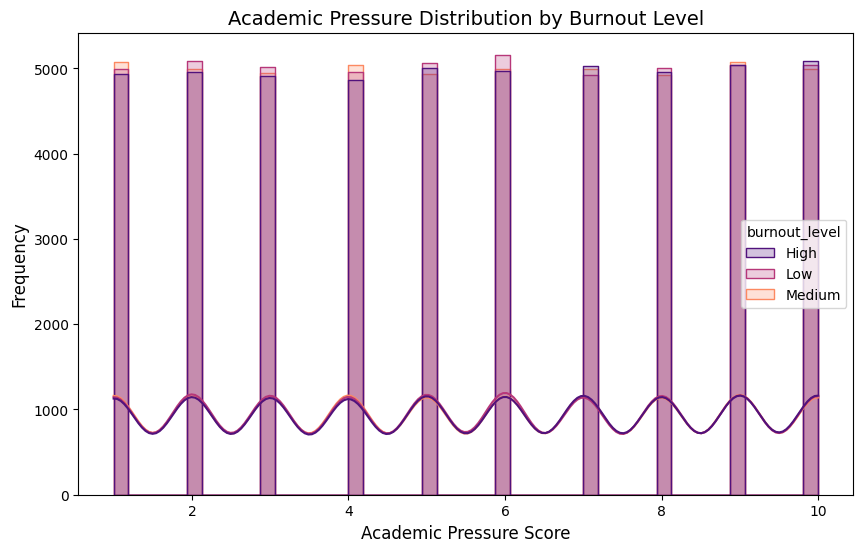

In [ ]:
#Hue Histogram
plt.figure(figsize=(10, 6))
# Using academic_pressure_score as it's a key factor in your dataset
sns.histplot(data=df, x='academic_pressure_score', hue='burnout_level',
             kde=True, element="step", palette='magma')

plt.title('Academic Pressure Distribution by Burnout Level', fontsize=14)
plt.xlabel('Academic Pressure Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

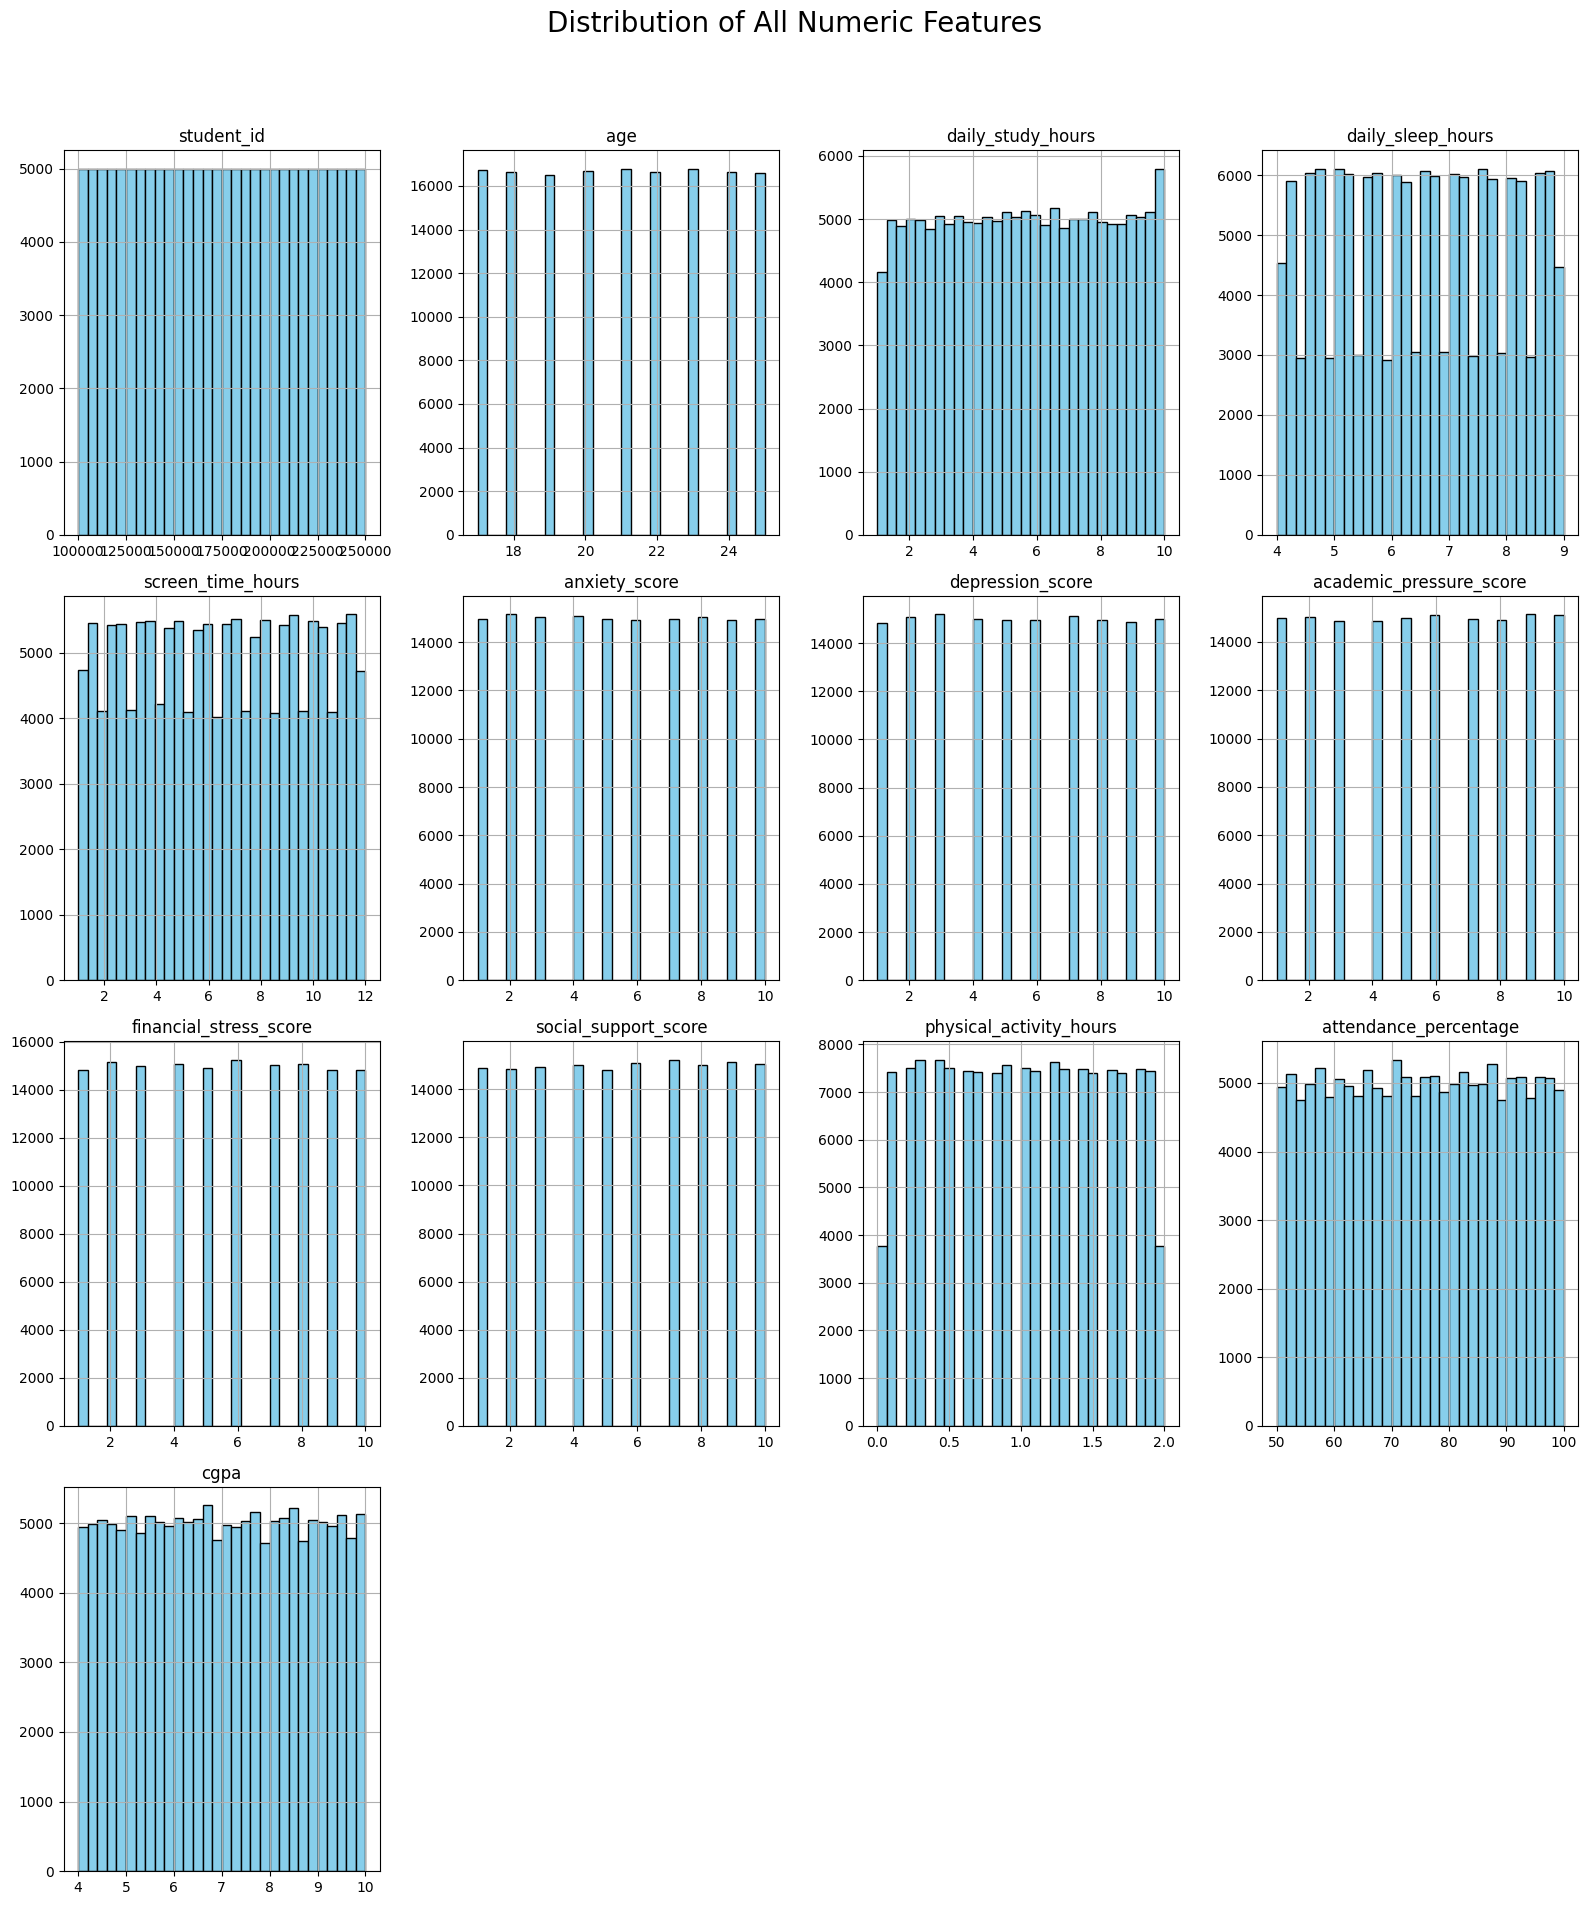

In [ ]:
#Grid Histogram
# This creates a histogram for every numeric column in your CSV
df.hist(figsize=(16, 20), bins=30, color='skyblue', edgecolor='black')
plt.suptitle('Distribution of All Numeric Features', fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

/tmp/ipykernel_725/3266592892.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='burnout_level', y='academic_pressure_score', data=df, palette='Set2')


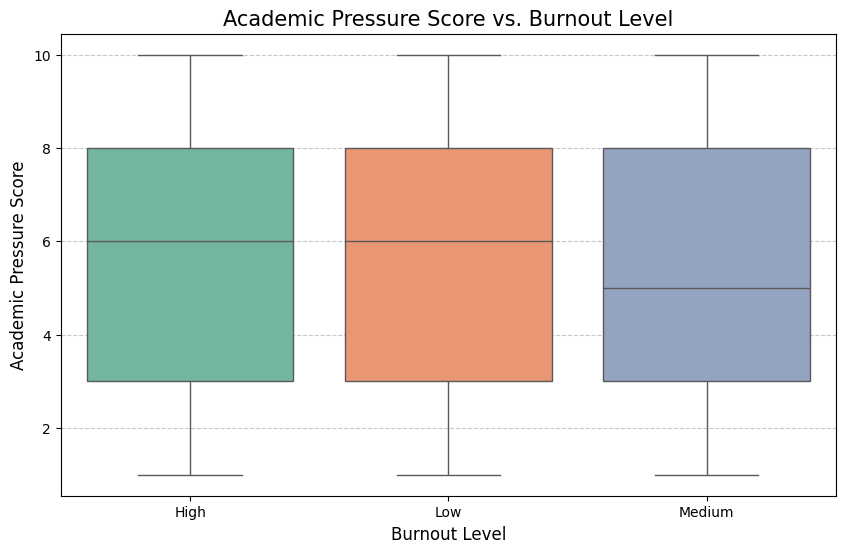

In [ ]:
#Boxplot

plt.figure(figsize=(10, 6))

# academic_pressure_score is a perfect choice for this
sns.boxplot(x='burnout_level', y='academic_pressure_score', data=df, palette='Set2')

plt.title('Academic Pressure Score vs. Burnout Level', fontsize=15)
plt.xlabel('Burnout Level', fontsize=12)
plt.ylabel('Academic Pressure Score', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [ ]:
df.head(6)

,student_id,age,gender,course,year,daily_study_hours,daily_sleep_hours,screen_time_hours,stress_level,anxiety_score,depression_score,academic_pressure_score,financial_stress_score,social_support_score,physical_activity_hours,sleep_quality,attendance_percentage,cgpa,internet_quality,burnout_level
0,100001,23,Male,BTech,1st,4.3,6.8,6.1,High,10,3,4,2,6,1.8,Average,66.5,9.63,Good,High
1,100002,20,Male,BTech,3rd,1.4,4.7,3.0,High,2,10,8,5,9,1.9,Poor,55.8,6.04,Poor,Low
2,100003,24,Female,BCA,4th,3.7,4.8,1.5,Low,2,7,8,6,3,0.8,Good,85.0,8.31,Good,High
3,100004,21,Male,BSc,4th,1.6,6.7,7.0,High,3,3,4,9,9,0.7,Poor,89.1,5.95,Good,High
4,100005,23,Other,BSc,4th,2.0,6.7,5.4,High,7,7,6,4,4,1.7,Good,58.7,8.51,Good,Low
5,100006,19,Male,BSc,3rd,8.2,4.8,4.1,High,8,4,9,8,2,1.9,Poor,51.7,6.82,Average,Low


In [ ]:
print("Shape of the dataset: ",df.shape)

Shape of the dataset:  (150000, 20)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 20 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   student_id               150000 non-null  int64  
 1   age                      150000 non-null  int64  
 2   gender                   150000 non-null  object 
 3   course                   150000 non-null  object 
 4   year                     150000 non-null  object 
 5   daily_study_hours        150000 non-null  float64
 6   daily_sleep_hours        150000 non-null  float64
 7   screen_time_hours        150000 non-null  float64
 8   stress_level             150000 non-null  object 
 9   anxiety_score            150000 non-null  int64  
 10  depression_score         150000 non-null  int64  
 11  academic_pressure_score  150000 non-null  int64  
 12  financial_stress_score   150000 non-null  int64  
 13  social_support_score     150000 non-null  int64  
 14  phys

In [ ]:
numerical_data = df.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 13 numerical features: 

['student_id', 'age', 'daily_study_hours', 'daily_sleep_hours', 'screen_time_hours', 'anxiety_score', 'depression_score', 'academic_pressure_score', 'financial_stress_score', 'social_support_score', 'physical_activity_hours', 'attendance_percentage', 'cgpa']


In [ ]:
categorical_data=df.select_dtypes(include= 'object')
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 7 categorical features: 

['gender', 'course', 'year', 'stress_level', 'sleep_quality', 'internet_quality', 'burnout_level']


In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
course,0
year,0
daily_study_hours,0
daily_sleep_hours,0
screen_time_hours,0
stress_level,0
anxiety_score,0


In [ ]:
df.describe(include='all')

,student_id,age,gender,course,year,daily_study_hours,daily_sleep_hours,screen_time_hours,stress_level,anxiety_score,depression_score,academic_pressure_score,financial_stress_score,social_support_score,physical_activity_hours,sleep_quality,attendance_percentage,cgpa,internet_quality,burnout_level
count,150000.000000,150000.000000,150000,150000,150000,150000.000000,150000.000000,150000.000000,150000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000,150000.000000,150000.000000,150000,150000
unique,NaN,NaN,3,6,4,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,3,3
top,NaN,NaN,Other,MBA,1st,NaN,NaN,NaN,High,NaN,NaN,NaN,NaN,NaN,NaN,Good,NaN,NaN,Average,Low
freq,NaN,NaN,50048,25231,37680,NaN,NaN,NaN,50295,NaN,NaN,NaN,NaN,NaN,NaN,50143,NaN,NaN,50138,50265
mean,175000.500000,21.000380,NaN,NaN,NaN,5.507869,6.499361,6.502819,NaN,5.493907,5.497360,5.507427,5.496027,5.516060,0.998115,NaN,75.009528,6.997389,NaN,NaN
std,43301.414527,2.581216,NaN,NaN,NaN,2.595592,1.443859,3.178948,NaN,2.872607,2.869022,2.875524,2.864698,2.870493,0.578866,NaN,14.409510,1.732180,NaN,NaN
min,100001.000000,17.000000,NaN,NaN,NaN,1.000000,4.000000,1.000000,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,NaN,50.000000,4.000000,NaN,NaN
25%,137500.750000,19.000000,NaN,NaN,NaN,3.300000,5.200000,3.700000,NaN,3.000000,3.000000,3.000000,3.000000,3.000000,0.500000,NaN,62.500000,5.500000,NaN,NaN
50%,175000.500000,21.000000,NaN,NaN,NaN,5.500000,6.500000,6.500000,NaN,5.000000,5.000000,6.000000,6.000000,6.000000,1.000000,NaN,75.000000,6.990000,NaN,NaN
75%,212500.250000,23.000000,NaN,NaN,NaN,7.700000,7.700000,9.300000,NaN,8.000000,8.000000,8.000000,8.000000,8.000000,1.500000,NaN,87.500000,8.500000,NaN,NaN


In [ ]:
numerical_data.nunique()

,0
student_id,150000
age,9
daily_study_hours,91
daily_sleep_hours,51
screen_time_hours,111
anxiety_score,10
depression_score,10
academic_pressure_score,10
financial_stress_score,10
social_support_score,10


In [ ]:
categorical_data.nunique()

,0
gender,3
course,6
year,4
stress_level,3
sleep_quality,3
internet_quality,3
burnout_level,3


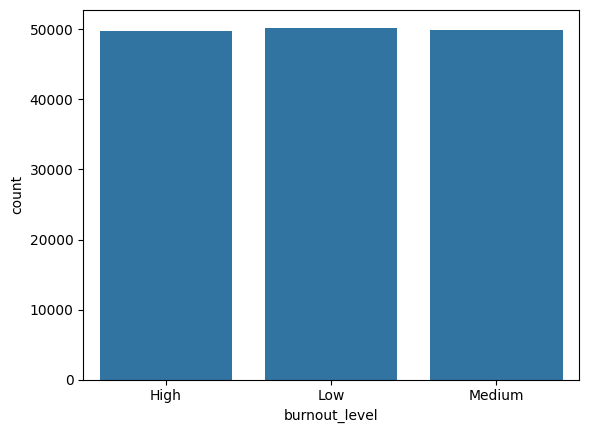

In [ ]:
sns.countplot(x='burnout_level', data=df)
plt.show()

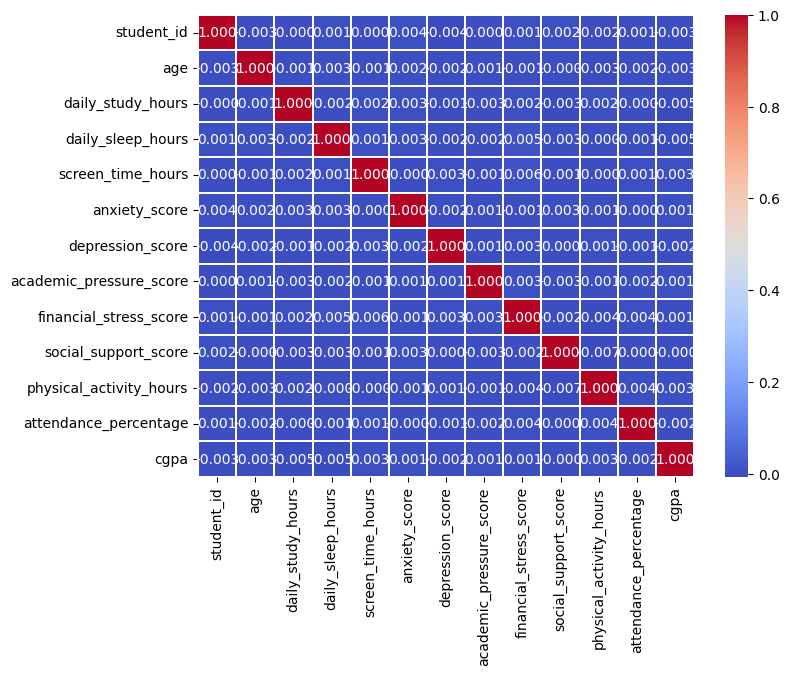

In [ ]:
#Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(numerical_data.corr(), annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

In [ ]:
print(df['burnout_level'].value_counts())

burnout_level
Low       50265
Medium    49969
High      49766
Name: count, dtype: int64


In [ ]:
#Encoding the target label
df['burnout_level'] = df['burnout_level'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2
})

In [ ]:
df['stress_level'] = df['stress_level'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2
})

df['sleep_quality'] = df['sleep_quality'].map({
    'Poor': 0,
    'Average': 1,
    'Good': 2
})

df['internet_quality'] = df['internet_quality'].map({
    'Poor': 0,
    'Average': 1,
    'Good': 2
})
df['year'] = df['year'].map({
    '1st': 0,
    '2nd': 1,
    '3rd': 2,
    '4th': 3
})

In [ ]:
#Dropping unnecessary cloumns
df = df.drop('student_id', axis=1)

In [ ]:
df['mental_health_index'] = (
    df['anxiety_score'] + df['depression_score']
) / 2

In [ ]:
df['lifestyle_balance'] = (
    df['daily_sleep_hours'] + df['physical_activity_hours']
) - df['screen_time_hours']

In [ ]:
df['academic_stress_index'] = (
    df['academic_pressure_score'] + df['daily_study_hours']
)

In [ ]:

df['support_stress_ratio'] = (
    df['social_support_score'] / (df['financial_stress_score'] + 1)
)

In [ ]:
df['performance_score'] = (
    df['cgpa'] * df['attendance_percentage']
)

In [ ]:
df['sleep_efficiency'] = (
    df['daily_sleep_hours'] * df['sleep_quality']
)

In [ ]:
df = pd.get_dummies(df, columns=[
    'gender', 'course', 'year',
    'stress_level', 'sleep_quality', 'internet_quality'
], drop_first=True)

In [ ]:
df['burnout_level'] = df['burnout_level'].apply(lambda x: 1 if x > 0 else 0)

In [ ]:
X = df.drop('burnout_level', axis=1)
y = df['burnout_level']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from cuml.svm import SVC
import cudf
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier

In [ ]:
from xgboost import XGBClassifier

In [ ]:
# ===== IMPORTS =====

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from cuml.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Utilities
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

# Plotting
import matplotlib.pyplot as plt


from xgboost import XGBClassifier

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rus = RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = rus.fit_resample(X_train_scaled, y_train)

print(f"Original dataset shape: {X_train.shape}")
print(f"Resampled dataset shape: {X_resampled.shape}")

Original dataset shape: (120000, 34)
Resampled dataset shape: (80424, 34)


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "MLP": MLPClassifier(max_iter=1000),



    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),

    "SVM Linear": SVC(
        kernel='linear',
        probability=True,
        class_weight='balanced',
        tol=1e-2,
        max_iter=10000
    ),

    "SVM RBF": SVC(
        kernel='rbf',
        probability=True,
        gamma='scale',
        class_weight='balanced',
        tol=1e-2,
        max_iter=10000
    ),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss')
}

In [ ]:
from imblearn.over_sampling import SMOTE


sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X_train_scaled, y_train)


Logistic Regression
Accuracy: 0.49903333333333333
Confusion Matrix:
 [[ 5092  4961]
 [10068  9879]]


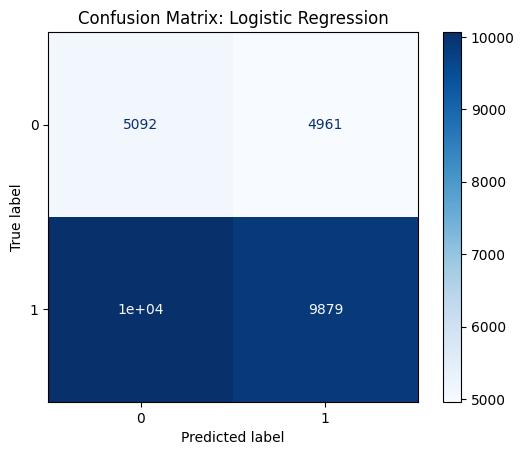


KNN
Accuracy: 0.49006666666666665
Confusion Matrix:
 [[ 5250  4803]
 [10495  9452]]


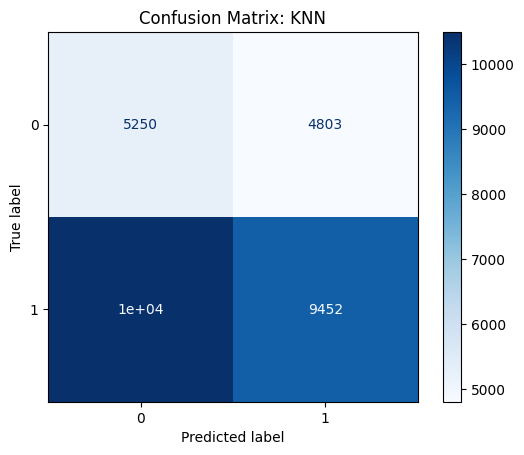


Decision Tree
Accuracy: 0.5468666666666666
Confusion Matrix:
 [[ 3633  6420]
 [ 7174 12773]]


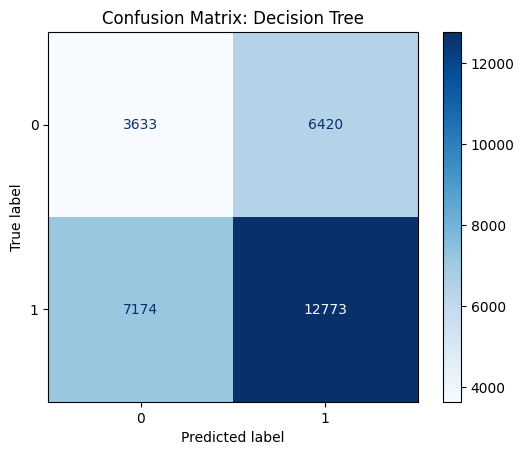


Random Forest
Accuracy: 0.6576
Confusion Matrix:
 [[  264  9789]
 [  483 19464]]


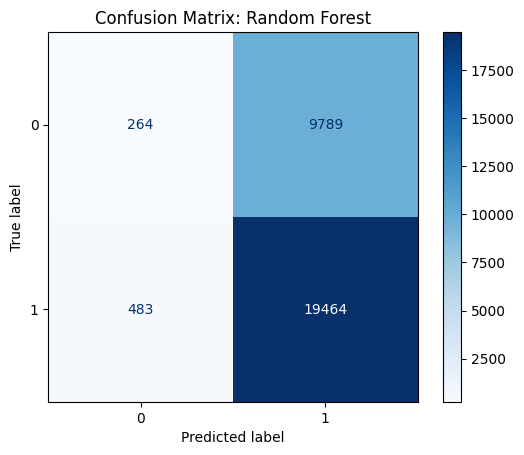


MLP
Accuracy: 0.5646
Confusion Matrix:
 [[ 2842  7211]
 [ 5851 14096]]


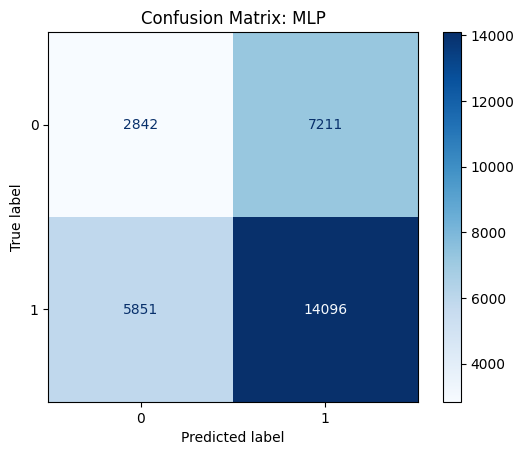


Naive Bayes
Accuracy: 0.5022333333333333
Confusion Matrix:
 [[ 4729  5324]
 [ 9609 10338]]


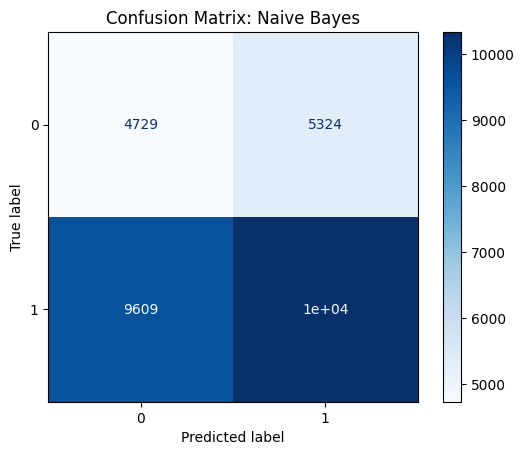


Gradient Boosting
Accuracy: 0.6376666666666667
Confusion Matrix:
 [[  791  9262]
 [ 1608 18339]]


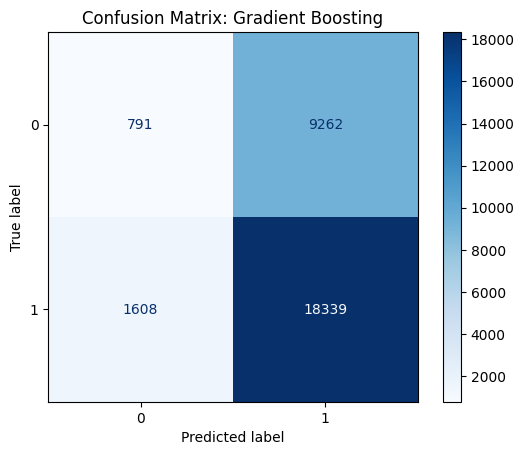


AdaBoost
Accuracy: 0.5259666666666667
Confusion Matrix:
 [[ 4186  5867]
 [ 8354 11593]]


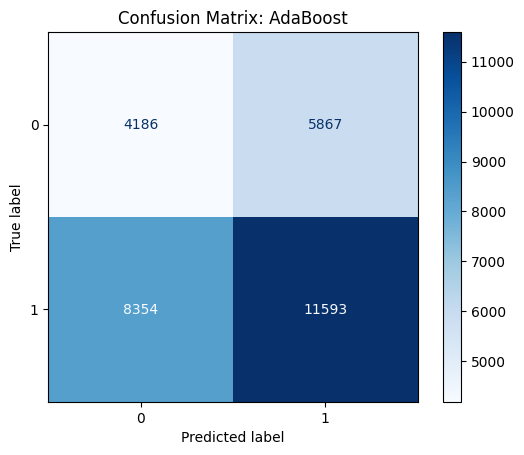


SVM Linear
Accuracy: 0.478
Confusion Matrix:
 [[ 5880  4173]
 [11487  8460]]


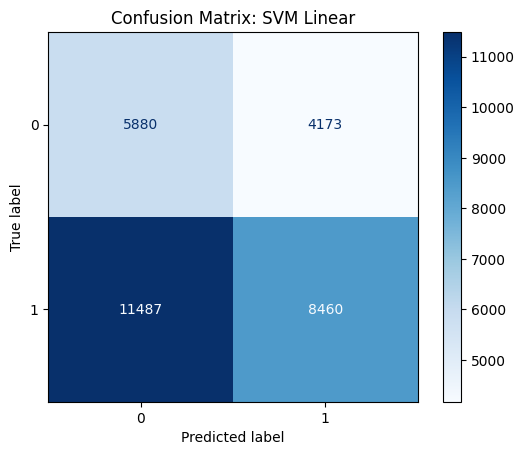


SVM RBF
Accuracy: 0.5354666666666666
Confusion Matrix:
 [[ 4140  5913]
 [ 8023 11924]]


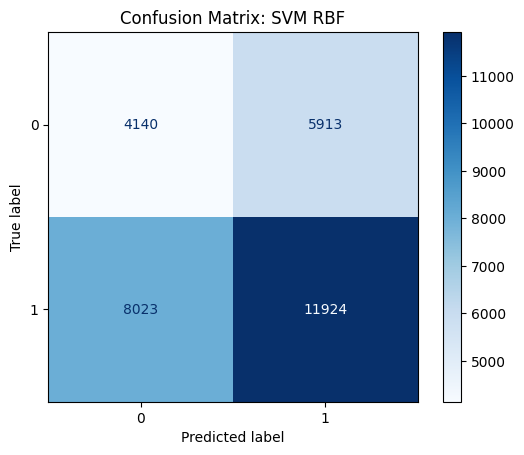

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [19:18:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost
Accuracy: 0.6602333333333333
Confusion Matrix:
 [[  158  9895]
 [  298 19649]]


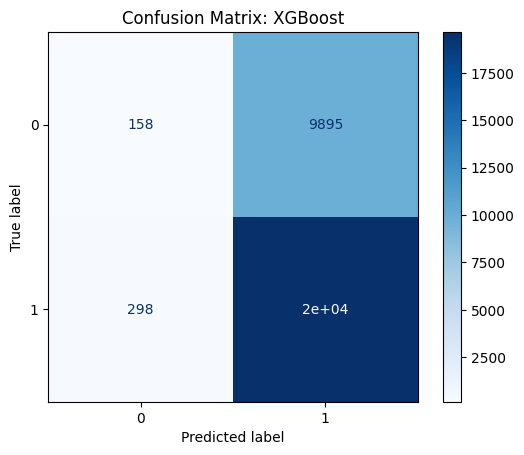

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

results = {}

for name, model in models.items():
    # Train
    model.fit(X_resampled, y_resampled)

    # Predict
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print(f"\n{name}")
    print("Accuracy:", acc)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    # Plot
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

In [ ]:
import pandas as pd

results_df = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"])
results_df = results_df.sort_values(by="Accuracy", ascending=False)

print(results_df)

                  Model  Accuracy
10              XGBoost  0.660233
3         Random Forest  0.657600
6     Gradient Boosting  0.637667
4                   MLP  0.564600
2         Decision Tree  0.546867
9               SVM RBF  0.535467
7              AdaBoost  0.525967
5           Naive Bayes  0.502233
0   Logistic Regression  0.499033
1                   KNN  0.490067
8            SVM Linear  0.478000


In [ ]:
best_model_name = results_df.iloc[0]["Model"]
print("Best model is:", best_model_name)

Best model is: XGBoost



Model: Logistic Regression
Accuracy:  0.4990
Precision: 0.6657
Recall:    0.4953
F1 Score:  0.5680
ROC-AUC:   0.4997


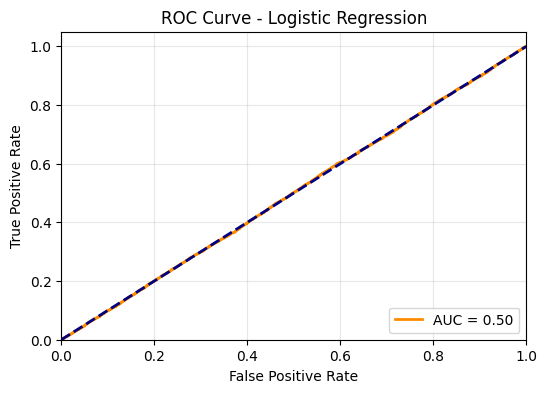


Model: KNN
Accuracy:  0.4901
Precision: 0.6631
Recall:    0.4739
F1 Score:  0.5527
ROC-AUC:   0.5011


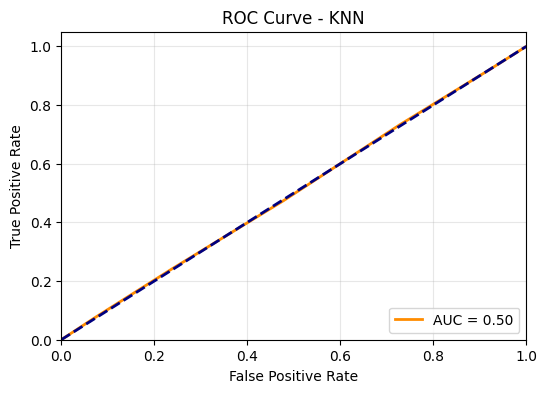


Model: Decision Tree
Accuracy:  0.5469
Precision: 0.6655
Recall:    0.6403
F1 Score:  0.6527
ROC-AUC:   0.5009


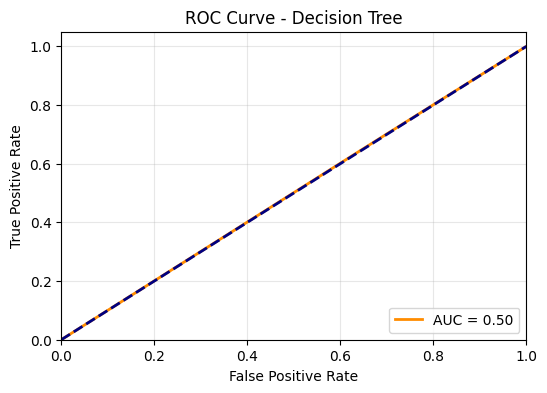


Model: Random Forest
Accuracy:  0.6576
Precision: 0.6654
Recall:    0.9758
F1 Score:  0.7912
ROC-AUC:   0.5070


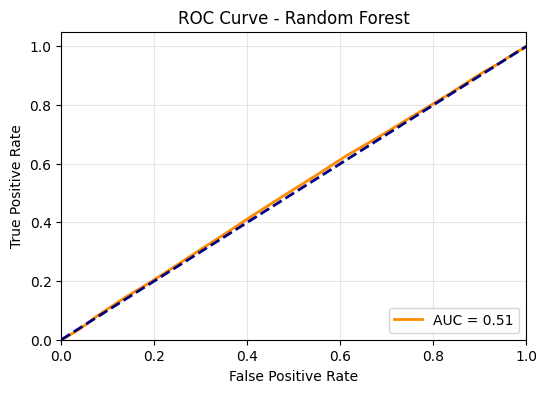


Model: MLP
Accuracy:  0.5646
Precision: 0.6616
Recall:    0.7067
F1 Score:  0.6834
ROC-AUC:   0.4979


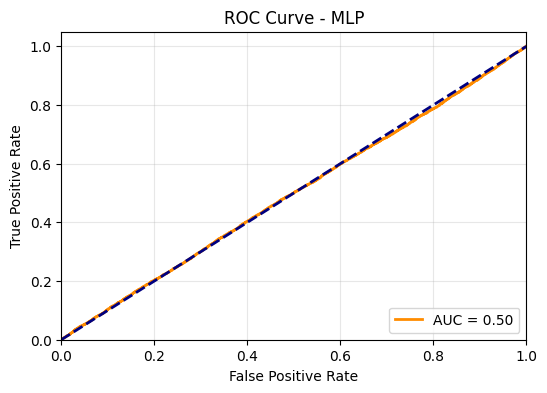


Model: Naive Bayes
Accuracy:  0.5022
Precision: 0.6601
Recall:    0.5183
F1 Score:  0.5806
ROC-AUC:   0.4962


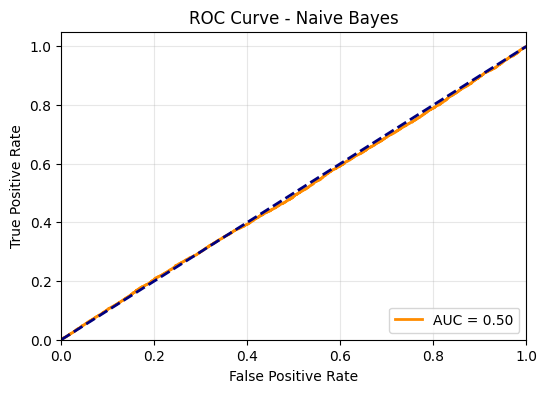


Model: Gradient Boosting
Accuracy:  0.6377
Precision: 0.6644
Recall:    0.9194
F1 Score:  0.7714
ROC-AUC:   0.4990


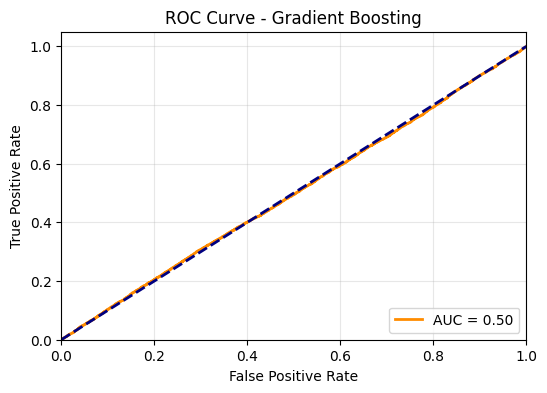


Model: AdaBoost
Accuracy:  0.5260
Precision: 0.6640
Recall:    0.5812
F1 Score:  0.6198
ROC-AUC:   0.4982


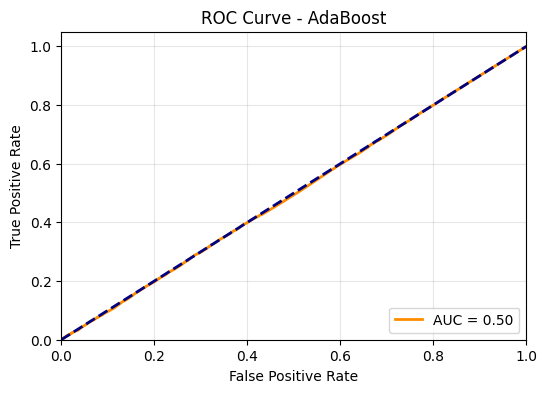


Model: SVM Linear
Accuracy:  0.4780
Precision: 0.6697
Recall:    0.4241
F1 Score:  0.5193
ROC-AUC:   0.5022


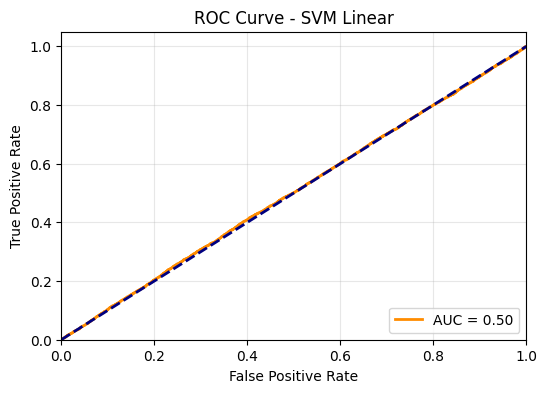


Model: SVM RBF
Accuracy:  0.5355
Precision: 0.6685
Recall:    0.5978
F1 Score:  0.6312
ROC-AUC:   0.5071


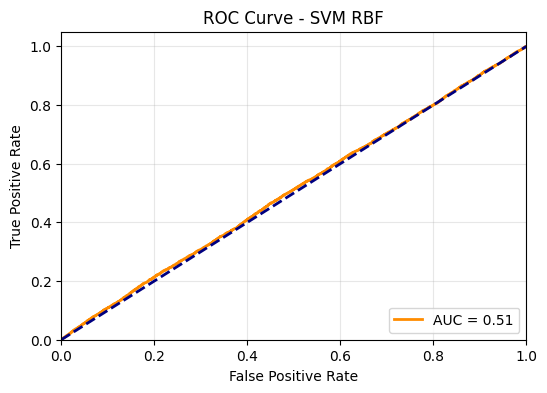


Model: XGBoost
Accuracy:  0.6602
Precision: 0.6651
Recall:    0.9851
F1 Score:  0.7940
ROC-AUC:   0.5051


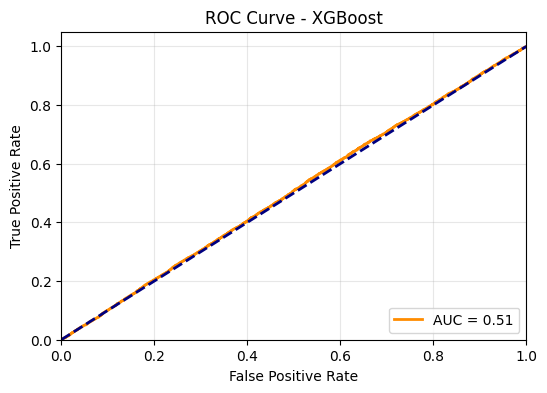

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

results = {}

for name, model in models.items():
    print("\n==============================")
    print("Model:", name)

    try:
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test_scaled)[:, 1]
        else:
            y_prob = model.decision_function(X_test_scaled)

        roc_auc = roc_auc_score(y_test, y_prob)
    except Exception as e:
        print(f"Skipping ROC for {name}: {e}")
        print("Make sure you set probability=True for SVM models.")
        continue

    # Predict for hard metrics
    y_pred = model.predict(X_test_scaled)

    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Store
    results[name] = {
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

    # Print
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")


    #ROC CURVE

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--', lw=2) # Diagonal baseline
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {name}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Accuracy", ascending=False)

print(results_df)

                     Accuracy  Precision    Recall  F1 Score   ROC-AUC
XGBoost              0.660233   0.665076  0.985060  0.794043  0.505073
Random Forest        0.657600   0.665368  0.975786  0.791220  0.506982
Gradient Boosting    0.637667   0.664432  0.919386  0.771389  0.499036
MLP                  0.564600   0.661567  0.706673  0.683376  0.497931
Decision Tree        0.546867   0.665503  0.640347  0.652683  0.500866
SVM RBF              0.535467   0.668498  0.597784  0.631167  0.507113
AdaBoost             0.525967   0.663975  0.581190  0.619831  0.498181
Naive Bayes          0.502233   0.660069  0.518273  0.580640  0.496183
Logistic Regression  0.499033   0.665701  0.495262  0.567971  0.499683
KNN                  0.490067   0.663066  0.473856  0.552716  0.501125
SVM Linear           0.478000   0.669675  0.424124  0.519337  0.502168
